In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [4]:
X , y = fetch_openml(data_id=40996,as_frame=False,return_X_y=True,parser="auto")
X = np.array(X,dtype=np.float32)
y = np.array(y,dtype=np.float32)

print(f"shape of data : {X.shape}")
print(f"number of samples : {X.shape[0]}")
print(f"number of features : {X.shape[1]}")
print(f"number of classes : {len(np.unique(y))}")
print(f"Pixel value range : [{X.min():.0f}, {X.max():.0f}]")


shape of data : (70000, 784)
number of samples : 70000
number of features : 784
number of classes : 10
Pixel value range : [0, 255]


### 1. How is a single image represented in the dataset?

In [5]:
single_image = X[0]

print("Single image representation :  \n",single_image)

Single image representation :  
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   1.   0.
   0.  13.  73.   0.   0.   1.   4.   0.   0.   0.   0.   1.   1.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   3.   0.
  36. 136. 127.  62.  54.   0.   0.   0.   1.   3.   4.   0.   0.   3.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   6.   0.
 102. 204. 176. 134. 144. 123.  23.   0.   0.   0.   0.  12.  10.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
 155. 236. 207. 178. 107. 156. 161. 109.  64

### 2. What are the minimum and maximum values that a pixel can have for the images in the dataset?

In [6]:
min_pixel = np.min(X)
max_pixel = np.max(X)

print(f"Minimum pixel value: {min_pixel}")
print(f"Maximum pixel value: {max_pixel}")

Minimum pixel value: 0.0
Maximum pixel value: 255.0


### 3. What do the numerical labels in the dataset represent? How do you know that?

In [7]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
example_labels = np.random.choice(y.astype(int), 10, replace=False)
print("example labels : mapped class names")
for i in example_labels:
    print(f"\t\t\t {i} : {class_names[i]}")

example labels : mapped class names
			 5 : Sandal
			 9 : Ankle boot
			 6 : Shirt
			 2 : Pullover
			 7 : Sneaker
			 1 : Trouser
			 5 : Sandal
			 1 : Trouser
			 4 : Coat
			 4 : Coat


### 4. Present a plot or table that displays several random images from each class.

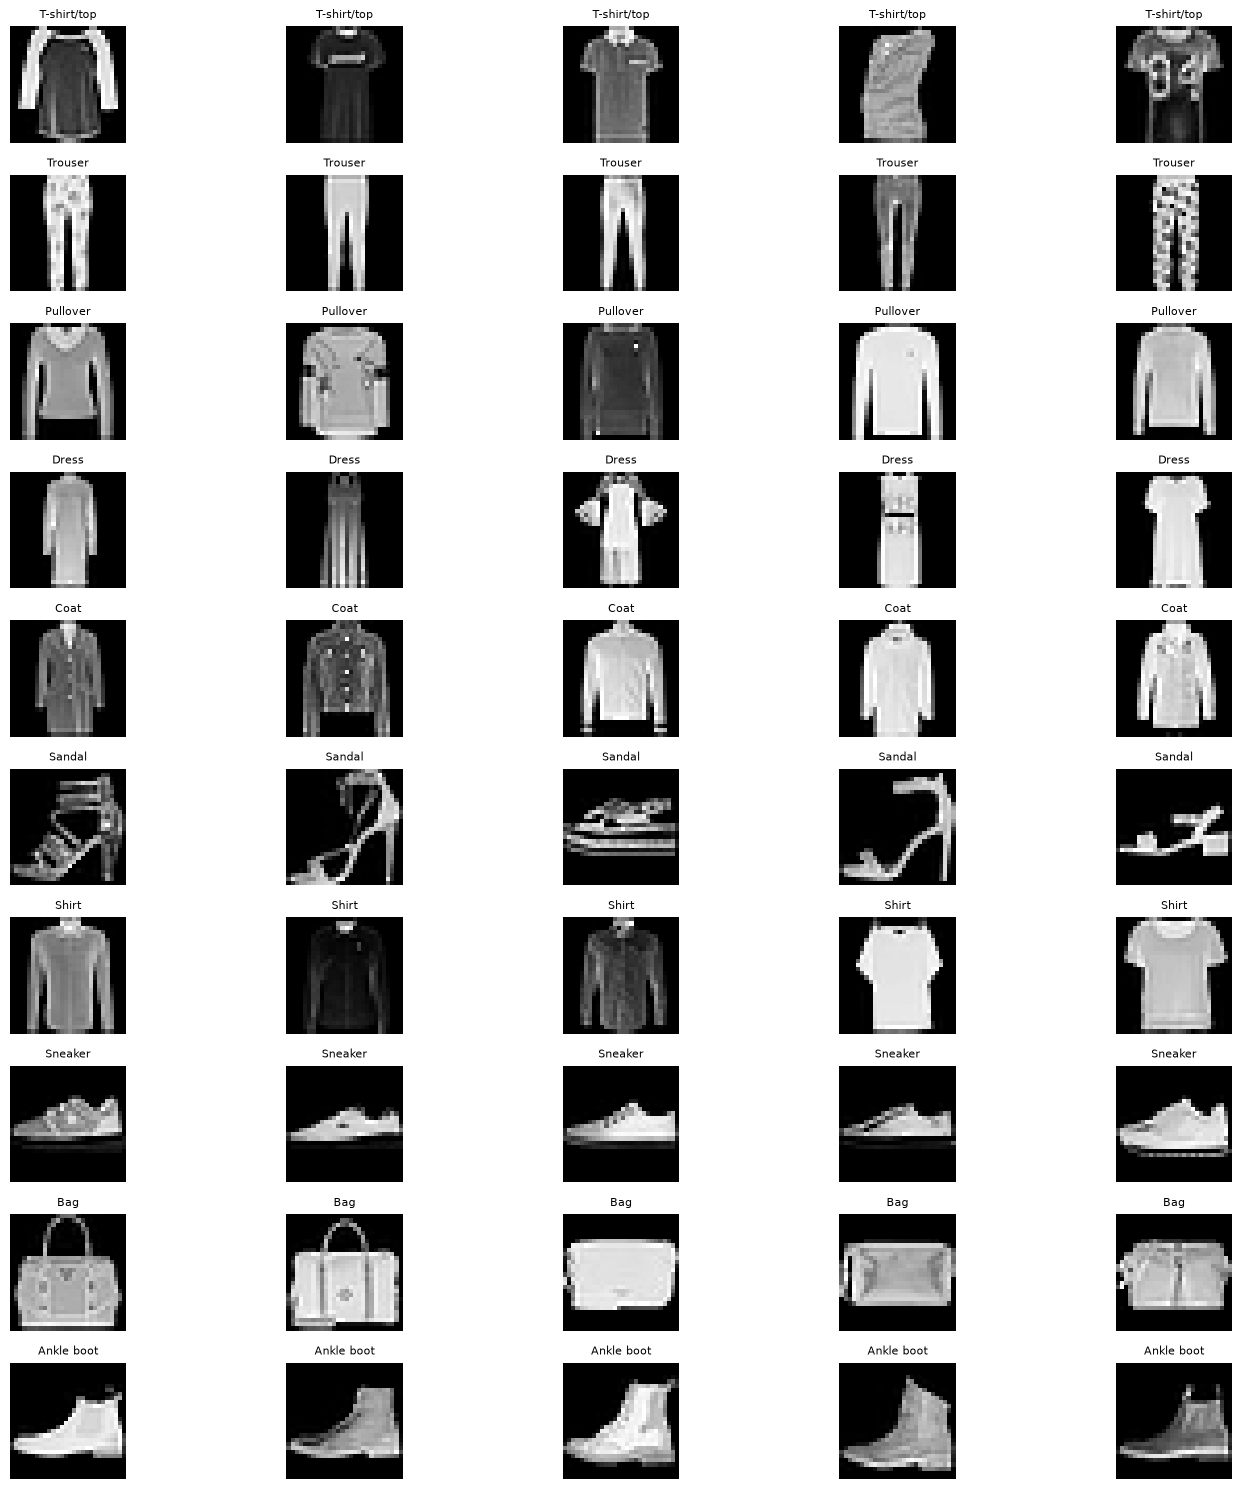

In [8]:
fig, axes = plt.subplots(10, 5, figsize=(15, 15))

for i in range(10):  # For each class
    # Find all images of this class
    class_samples = X[y == i]
    # Select 5 random images
    random_indices = np.random.choice(len(class_samples), 5, replace=False)

    for j, idx in enumerate(random_indices):
        axes[i, j].imshow(class_samples[idx].reshape(28,28), cmap='gray')
        axes[i, j].set_title(class_names[i], fontsize=8)
        axes[i, j].axis('off')


plt.tight_layout()
plt.show()

### 5. How does the frequency of class labels compare to one another? Illustrate your answer using a bar plot.


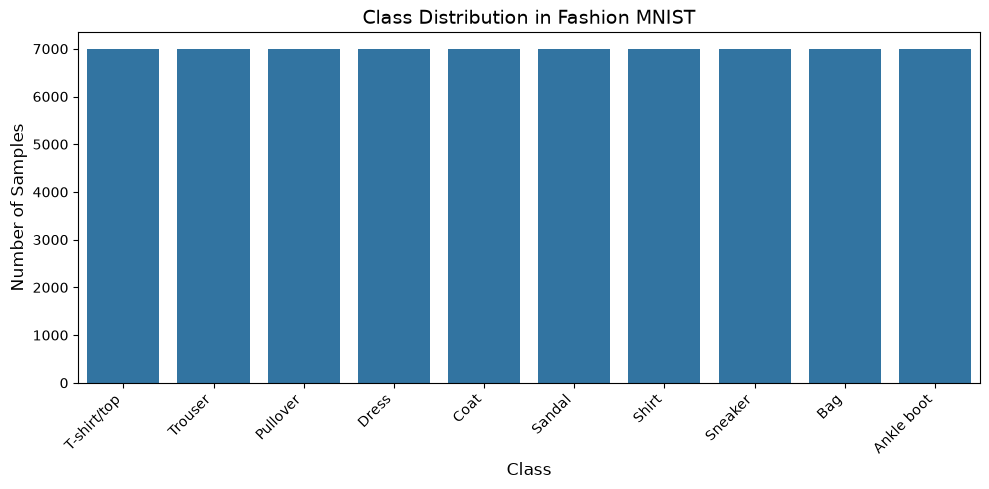

In [9]:
plt.figure(figsize=(10,5))
sns.countplot(x=y)
plt.title("Class Distribution in Fashion MNIST", fontsize=14)
plt.xlabel("Class", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)
plt.xticks(ticks=range(10), labels=class_names, rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 6. Randomly sample 100 data items from each class, and perform the following tasks on this subset of the dataset:

#### (a) Utilize t-SNE (t-distributed Stochastic Neighbor Embedding) to reduce the dimensionality of the dataset to three dimensions.

In [10]:
print("Sampling 100 items from each class...")
sampled_X, sampled_y = [], []
for i in range(10):
    idx = np.where(y == i)[0]
    chosen = np.random.choice(idx, 100, replace=False)
    sampled_X.append(X[chosen])
    sampled_y.extend([i]*100)
sampled_X = np.vstack(sampled_X)
sampled_y = np.array(sampled_y)

print(f"Number of selected samples: {sampled_X.shape[0]}")

# Run t-SNE
print("Running t-SNE (about 1 minute)...")
tsne = TSNE(n_components=3, random_state=42, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(sampled_X)
print("t-SNE completed!\n")
print("Shape of the reduced dataset:", X_tsne.shape)

Sampling 100 items from each class...
Number of selected samples: 1000
Running t-SNE (about 1 minute)...
t-SNE completed!

Shape of the reduced dataset: (1000, 3)


#### (b) Visualize the resulting data in a 3D scatter plot, using distinct colors to differentiate between classes.

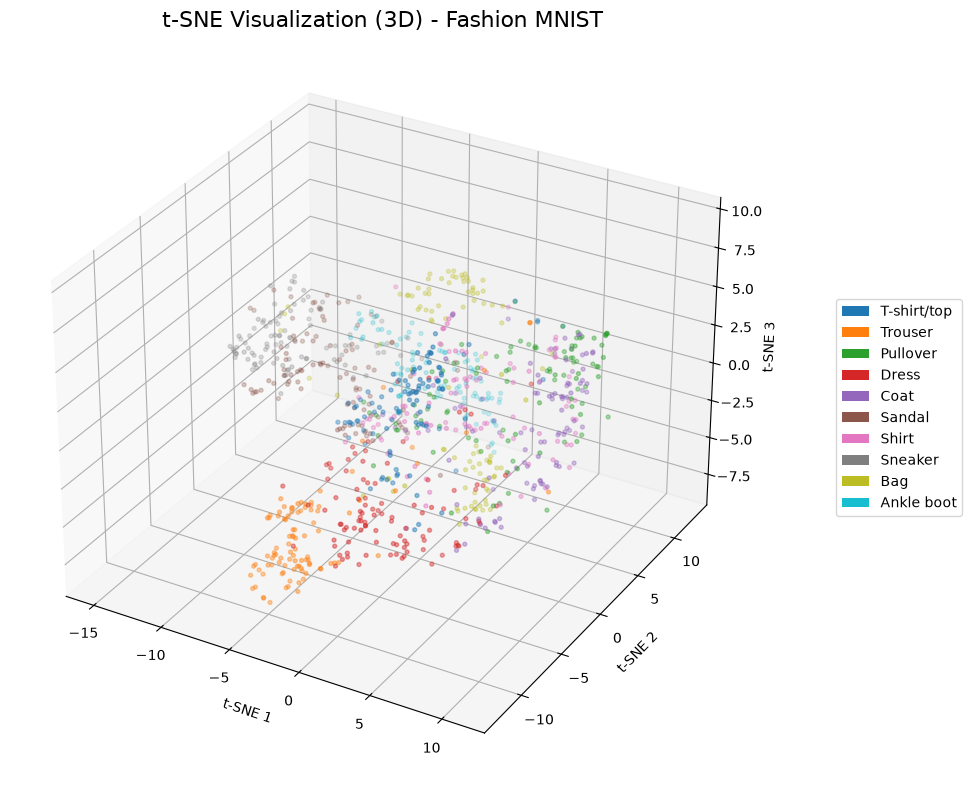

In [11]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot points with different colors
scatter = ax.scatter(X_tsne[:,0], X_tsne[:,1], X_tsne[:,2],
                     c=sampled_y, cmap='tab10', s=8, alpha=0.7)

ax.set_title("t-SNE Visualization (3D) - Fashion MNIST", fontsize=16)
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.set_zlabel("t-SNE 3")

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=plt.cm.tab10(i), label=class_names[i])
                   for i in range(10)]
ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.1, 0.5))

plt.tight_layout()
plt.show()

#### (c) Discuss the separability of the classes based on the visualization.

Based on the 3D t-SNE visualization:

✅ Classes that are well separated:
   • Trouser (blue) - completely separated from others
   • Sandal (pink) - distinct cluster
   • Sneaker (yellow) - distinct cluster
   • Bag (dark green) - distinct cluster
   • Ankle boot (purple) - distinct cluster

⚠️ Classes with overlap:
   • T-shirt/top (red) and Shirt (orange) - high overlap
   • Pullover (green) and Coat (dark blue) - high overlap
   • Dress (light blue) - overlaps with Pullover and Coat

💡 Conclusion:
   Classes with similar appearance are close together in t-SNE space.
   This indicates that the data has good separability,
   but for similar classes, the model may make errors.

 (d) Considering the use of KNN for classification in this assignment, what specific property of t-SNE enables it to effectively highlight class separability in the visualization created in question 6c?
Please provide an explanation and reference a relevant textbook or academic paper that discusses this property

🔑 Key Property: Local Neighborhood Preservation

📖 Simple Explanation:
   t-SNE keeps points that are close in the original high-dimensional space
   close together in the new low-dimensional space.

🔬 Example:
   • Two similar T-shirt images → placed close together in t-SNE
   • A T-shirt and a Trouser (completely different) → placed far apart in t-SNE

🎯 Result:
   This is why similar classes appear together and different classes
   appear separated in the visualization.

📚 Reference:
   Maaten, L. V. D., & Hinton, G. (2008).
   Visualizing data using t-SNE.
   Journal of machine learning research, 9(Nov), 2579-2605.

# Preprocessing


### Data Splitting

In [12]:
# Split data into 70-15-15
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"Training: {X_train.shape[0]} samples")
print(f"Validation: {X_val.shape[0]} samples")
print(f"Test: {X_test.shape[0]} samples")

Training: 49000 samples
Validation: 10500 samples
Test: 10500 samples


### Preprocessing function

In [35]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, roc_auc_score)
from sklearn.preprocessing import MinMaxScaler, StandardScaler

def preprocess(train, val, variance_ratio=0.90, scaler_type='minmax'):
    if scaler_type == 'minmax':
        scaler = MinMaxScaler()
        train_scaled = scaler.fit_transform(train)
        val_scaled   = scaler.transform(val)
    elif scaler_type == 'standard':
        scaler = StandardScaler()
        train_scaled = scaler.fit_transform(train)
        val_scaled   = scaler.transform(val)
    else:
        train_scaled = train.copy()
        val_scaled   = val.copy()

    pca = PCA(n_components=variance_ratio, random_state=42)
    train_pca = pca.fit_transform(train_scaled)
    val_pca   = pca.transform(val_scaled)
    return train_pca, val_pca, pca.n_components_

def knn_predictor(train_data, train_labels, test_data, k=5, metric='euclidean',
                  weighted=True, eps=1e-5, return_scores=False):

    classes = np.unique(train_labels)

    def vote(neighbor_list):
        score_board = {c: 0.0 for c in classes}
        if weighted:
            for lbl, dist in neighbor_list:
                score_board[lbl] += 1.0 / (dist + eps)
        else:
            for lbl, _ in neighbor_list:
                score_board[lbl] += 1.0

        total = sum(score_board.values()) + 1e-12
        probs = np.array([score_board[c] / total for c in classes])
        pred  = classes[np.argmax(probs)]
        return pred, probs

    preds, scores = [], []
    for sample in test_data:
        if metric == 'euclidean':
            dists = np.sqrt(np.sum((train_data - sample)**2, axis=1))
        else:
            dists = np.sum(np.abs(train_data - sample), axis=1)

        idxs = np.argsort(dists)[:k]
        neighbors = [(train_labels[i], dists[i]) for i in idxs]
        pred, probs = vote(neighbors)
        preds.append(pred)
        scores.append(probs)

    preds = np.array(preds)
    if return_scores:
        return preds, np.array(scores)
    return preds



### implement the K-Nearest Neighbors (KNN) algorithm from scratch <br>
The implementation includes:

- **Distance calculation** using Euclidean distance
- **K-nearest neighbor search** using sorting
- **Weighted voting** based on inverse distance

In [31]:
def knn_predictor(train_data, train_labels, test_data, k=5, metric='euclidean',
                  weighted=True, eps=1e-5, return_scores=False):

    classes = np.unique(train_labels)

    def vote(neighbor_list):
        score_board = {c: 0.0 for c in classes}
        if weighted:
            for lbl, dist in neighbor_list:
                score_board[lbl] += 1.0 / (dist + eps)
        else:
            for lbl, _ in neighbor_list:
                score_board[lbl] += 1.0

        total = sum(score_board.values()) + 1e-12
        probs = np.array([score_board[c] / total for c in classes])
        pred  = classes[np.argmax(probs)]
        return pred, probs

    preds, scores = [], []
    for sample in test_data:
        if metric == 'euclidean':
            dists = np.sqrt(np.sum((train_data - sample)**2, axis=1))
        else:
            dists = np.sum(np.abs(train_data - sample), axis=1)

        idxs = np.argsort(dists)[:k]
        neighbors = [(train_labels[i], dists[i]) for i in idxs]
        pred, probs = vote(neighbors)
        preds.append(pred)
        scores.append(probs)

    preds = np.array(preds)
    if return_scores:
        return preds, np.array(scores)
    return preds

In [36]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

def print_per_class_metrics(y_true, y_pred, y_scores, title=""):
    precision = precision_score(y_true, y_pred, average=None, zero_division=0)
    recall    = recall_score(y_true, y_pred, average=None, zero_division=0)
    f1        = f1_score(y_true, y_pred, average=None, zero_division=0)
    auc       = roc_auc_score(y_true, y_scores, multi_class='ovr', average=None)

    df = pd.DataFrame({
        'Class'     : class_names,
        'Precision' : np.round(precision, 4),
        'Recall'    : np.round(recall, 4),
        'F1-Score'  : np.round(f1, 4),
        'AUC'       : np.round(auc, 4)
    })

    print(f"\n{title}")
    print(df.to_string(index=False))
    print("-" * 65)
    print(f"Macro Avg → Precision: {precision.mean():.4f} | "
          f"Recall: {recall.mean():.4f} | F1: {f1.mean():.4f} | AUC: {auc.mean():.4f}")
    print(f"Accuracy  → {accuracy_score(y_true, y_pred):.4f}")
    print("=" * 65)
    return df

In [22]:
import time
from sklearn.model_selection import StratifiedShuffleSplit

In [37]:
USE_SUBSAMPLE = True
if USE_SUBSAMPLE:
    sss = StratifiedShuffleSplit(n_splits=1, train_size=10000, random_state=42)
    for idx, _ in sss.split(X_train, y_train):
        X_tr_sub = X_train[idx]
        y_tr_sub = y_train[idx]
    print(f"Using subsample: {len(y_tr_sub)} samples\n")
else:
    X_tr_sub, y_tr_sub = X_train, y_train

configs = [

    ('minmax',   0.85, 5, 'euclidean', True),
    ('minmax',   0.90, 5, 'euclidean', True),
    ('minmax',   0.90, 7, 'euclidean', True),
    ('minmax',   0.90, 7, 'manhattan', True),
    ('minmax',   0.90, 9, 'euclidean', True),
    ('minmax',   0.95, 7, 'euclidean', True),
    ('standard', 0.90, 7, 'euclidean', True),
    ('standard', 0.90, 7, 'manhattan', True),
    ('minmax',   0.90, 7, 'euclidean', False),
]

results = []

for i, (scaler_type, var, k, metric, weighted) in enumerate(configs, 1):
    print(f"\n[{i}/{len(configs)}] scaler={scaler_type} | var={var} | k={k} | "
          f"metric={metric} | weighted={weighted}")

    start = time.time()

    X_tr, X_va, n_comp = preprocess(X_tr_sub, X_val, variance_ratio=var, scaler_type=scaler_type)

    preds, scores = knn_predictor(
        X_tr, y_tr_sub, X_va,
        k=k, metric=metric, weighted=weighted, return_scores=True
    )

    acc       = accuracy_score(y_val, preds)
    prec      = precision_score(y_val, preds, average=None, zero_division=0)
    rec       = recall_score(y_val, preds, average=None, zero_division=0)
    f1        = f1_score(y_val, preds, average=None, zero_division=0)
    auc_cls   = roc_auc_score(y_val, scores, multi_class='ovr', average=None)
    auc_macro = float(auc_cls.mean())

    elapsed = time.time() - start


    title = (f"Config {i}: scaler={scaler_type}, var={var}, k={k}, "
             f"metric={metric}, weighted={weighted}")
    print_per_class_metrics(y_val, preds, scores, title=title)

    results.append({
        'scaler'      : scaler_type,
        'pca_var'     : var,
        'n_neighbors' : k,
        'metric'      : metric,
        'weighted'    : weighted,
        'n_components': n_comp,
        'accuracy'    : round(acc, 4),
        'macro_f1'    : round(float(f1.mean()), 4),
        'macro_auc'   : round(auc_macro, 4),
        'time_sec'    : round(elapsed, 1),
        'precision'   : np.round(prec, 4).tolist(),
        'recall'      : np.round(rec, 4).tolist(),
        'f1_score'    : np.round(f1, 4).tolist(),
        'auc'         : np.round(auc_cls, 4).tolist()
    })

Using subsample: 10000 samples


[1/9] scaler=minmax | var=0.85 | k=5 | metric=euclidean | weighted=True

Config 1: scaler=minmax, var=0.85, k=5, metric=euclidean, weighted=True
      Class  Precision  Recall  F1-Score    AUC
T-shirt/top     0.7706  0.8381    0.8029 0.9649
    Trouser     0.9832  0.9448    0.9636 0.9839
   Pullover     0.7405  0.7067    0.7232 0.9424
      Dress     0.8551  0.8657    0.8604 0.9767
       Coat     0.6992  0.7705    0.7331 0.9517
     Sandal     0.9630  0.8667    0.9123 0.9797
      Shirt     0.6352  0.5705    0.6011 0.8960
    Sneaker     0.8962  0.9048    0.9005 0.9832
        Bag     0.9565  0.9419    0.9491 0.9867
 Ankle boot     0.8821  0.9619    0.9203 0.9909
-----------------------------------------------------------------
Macro Avg → Precision: 0.8382 | Recall: 0.8371 | F1: 0.8366 | AUC: 0.9656
Accuracy  → 0.8371

[2/9] scaler=minmax | var=0.9 | k=5 | metric=euclidean | weighted=True

Config 2: scaler=minmax, var=0.9, k=5, metric=euclidean, weigh

In [38]:
df = pd.DataFrame(results).sort_values('accuracy', ascending=False)

print("\n" + "=" * 65)
print("SUMMARY - All Configurations (sorted by Accuracy)")
print("=" * 65)
print(df[['scaler', 'pca_var', 'n_neighbors', 'metric', 'weighted',
          'n_components', 'accuracy', 'macro_f1', 'macro_auc', 'time_sec']]
      .to_string(index=False))

best = df.iloc[0]
print("\n" + "=" * 65)
print("BEST CONFIGURATION")
print("=" * 65)
print(f"scaler       : {best['scaler']}")
print(f"pca_var      : {best['pca_var']}")
print(f"n_neighbors  : {best['n_neighbors']}")
print(f"metric       : {best['metric']}")
print(f"weighted     : {best['weighted']}")
print(f"n_components : {best['n_components']}")
print(f"Accuracy     : {best['accuracy']}")
print(f"Macro F1     : {best['macro_f1']}")
print(f"Macro AUC    : {best['macro_auc']}")


SUMMARY - All Configurations (sorted by Accuracy)
  scaler  pca_var  n_neighbors    metric  weighted  n_components  accuracy  macro_f1  macro_auc  time_sec
standard     0.90            7 manhattan      True           130    0.8420    0.8423     0.9737      55.1
standard     0.90            7 euclidean      True           130    0.8413    0.8414     0.9718      47.9
  minmax     0.90            7 manhattan      True            83    0.8412    0.8411     0.9736      29.1
  minmax     0.90            5 euclidean      True            83    0.8406    0.8401     0.9668      45.5
  minmax     0.90            7 euclidean      True            83    0.8392    0.8386     0.9724      31.0
  minmax     0.95            7 euclidean      True           183    0.8374    0.8373     0.9717      76.8
  minmax     0.90            7 euclidean     False            83    0.8373    0.8360     0.9717      29.5
  minmax     0.85            5 euclidean      True            43    0.8371    0.8366     0.9656      

PCA dimensions: 137


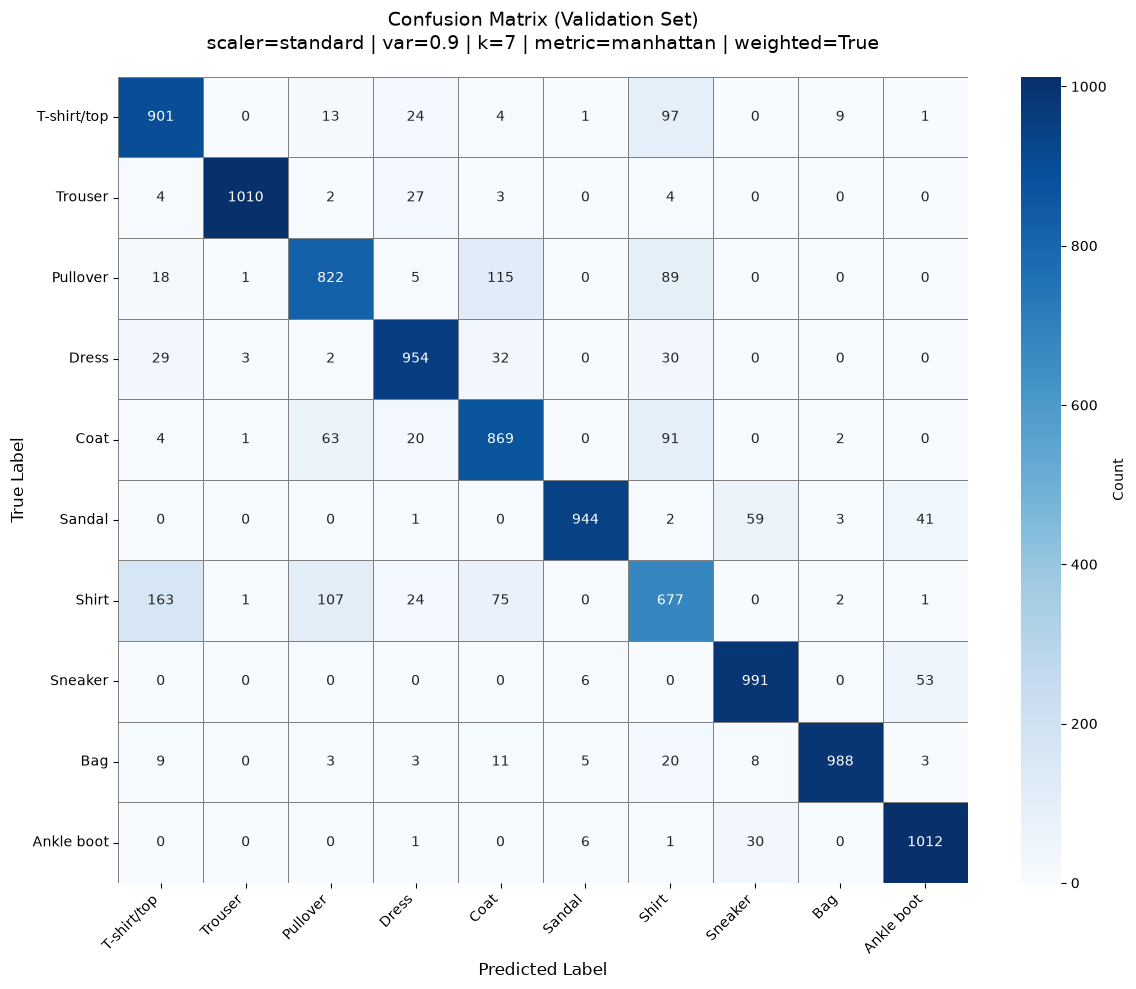

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_scaler   = 'standard'
best_var      = 0.90
best_k        = 7
best_metric   = 'manhattan'
best_weighted = True


X_tr, X_va, n_comp = preprocess(X_train, X_val,
                                 variance_ratio=best_var,
                                 scaler_type=best_scaler)

print(f"PCA dimensions: {n_comp}")

val_preds = knn_predictor(
    X_tr, y_train, X_va,
    k=best_k,
    metric=best_metric,
    weighted=best_weighted,
    return_scores=False
)


cm = confusion_matrix(y_val, val_preds)

plt.figure(figsize=(12, 10))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            linewidths=0.5,
            linecolor='gray',
            cbar_kws={'label': 'Count'})

plt.title(f'Confusion Matrix (Validation Set)\n'
          f'scaler={best_scaler} | var={best_var} | k={best_k} | '
          f'metric={best_metric} | weighted={best_weighted}',
          fontsize=14, pad=20)

plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

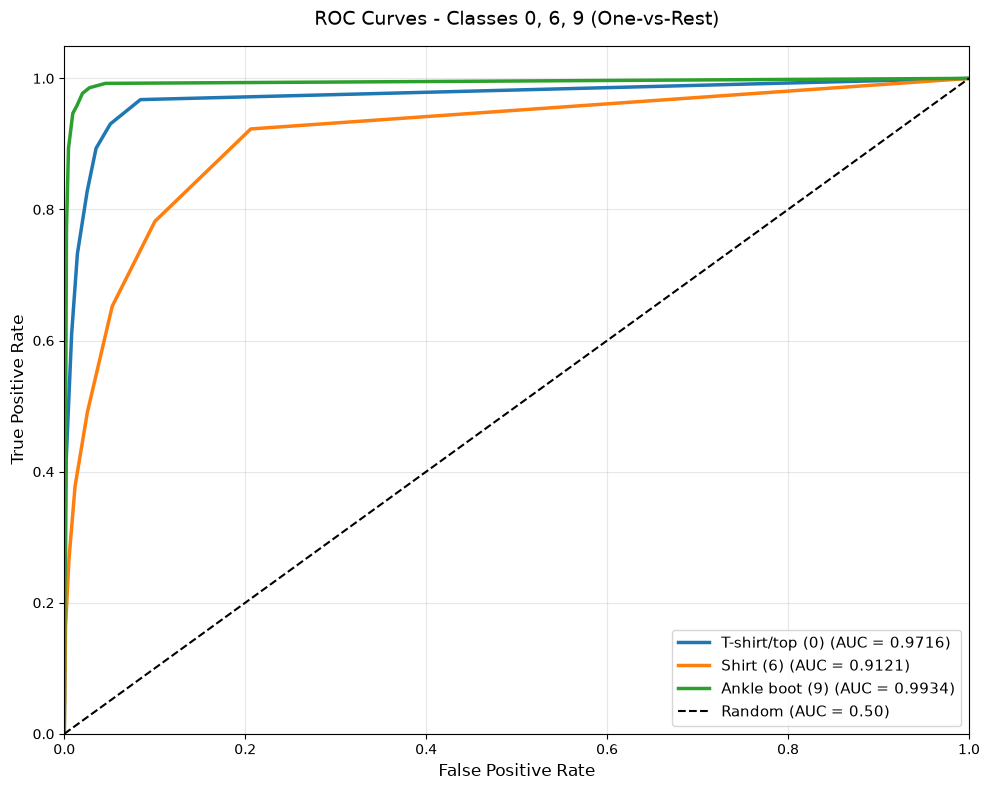

In [40]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

target_classes = [0, 6, 9]
class_names_map = {
    0: 'T-shirt/top (0)',
    6: 'Shirt (6)',
    9: 'Ankle boot (9)'
}

# Binarize کردن لیبل‌ها (One-vs-Rest)
y_val_bin = label_binarize(y_val, classes=np.arange(10))

# ----------------------------------------------------------
# رسم ROC
# ----------------------------------------------------------
plt.figure(figsize=(10, 8))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # آبی، نارنجی، سبز

for i, cls in enumerate(target_classes):
    fpr, tpr, _ = roc_curve(y_val_bin[:, cls], scores[:, cls])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, color=colors[i], lw=2.5,
             label=f'{class_names_map[cls]} (AUC = {roc_auc:.4f})')

# خط تصادفی
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves - Classes 0, 6, 9 (One-vs-Rest)', fontsize=14, pad=15)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()